In [ ]:

import zipfile
import os

zip_path = "/content/titanic.zip"
extract_path = "/content/titanic_data"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Files:", os.listdir(extract_path))


Dataset extracted successfully!
Files: ['test.csv', 'gender_submission.csv', 'train.csv']


In [ ]:

import pandas as pd
import os

# Find the CSV file inside the extracted folder
for root, dirs, files in os.walk("/content/titanic_data"):
    for file in files:
        if file == "train.csv":
            csv_path = os.path.join(root, file)

# Load the dataset
df = pd.read_csv(csv_path)

# Display the first 5 rows
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display column names and data types
print("\nDataset information:")
df.info()

# Check missing values in each column
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())


Dataset shape: (891, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare     

In [ ]:

# Fill missing ages with the median age
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing embarkation ports with the most common port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Fill missing fares, if any
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [ ]:

# Fill missing ages with the median age
df["Age"] = df["Age"].fillna(df["Age"].median())

# Fill missing embarkation ports with the most common port
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

# Fill missing fares with the median fare
df["Fare"] = df["Fare"].fillna(df["Fare"].median())

# Check missing values again
print("Missing values after cleaning:")
print(df.isnull().sum())


Missing values after cleaning:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64


In [ ]:

# Count survivors by gender
print("Survival count by gender:")
print(df.groupby("Sex")["Survived"].sum())

# Calculate survival rate by gender
print("\nSurvival rate by gender (%):")
print(df.groupby("Sex")["Survived"].mean() * 100)


Survival count by gender:
Sex
female    233
male      109
Name: Survived, dtype: int64

Survival rate by gender (%):
Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64


In [ ]:

# Count survivors by passenger class
print("Survivors by passenger class:")
print(df.groupby("Pclass")["Survived"].sum())

# Calculate survival rate by passenger class
print("\nSurvival rate by passenger class (%):")
print(df.groupby("Pclass")["Survived"].mean() * 100)


Survivors by passenger class:
Pclass
1    136
2     87
3    119
Name: Survived, dtype: int64

Survival rate by passenger class (%):
Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


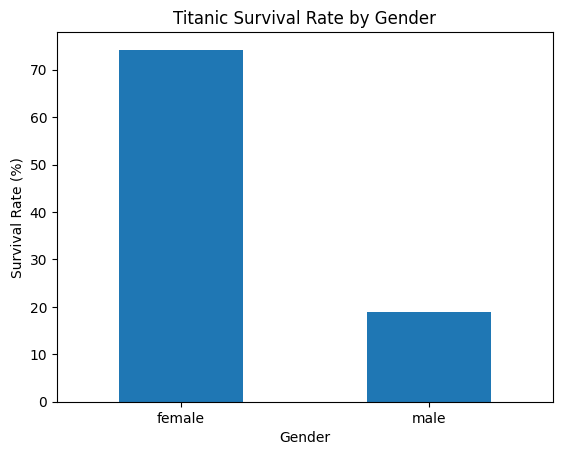

In [ ]:

import matplotlib.pyplot as plt

# Calculate survival rate by gender
survival_rate = df.groupby("Sex")["Survived"].mean() * 100

# Create bar chart
survival_rate.plot(kind="bar")

plt.title("Titanic Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()


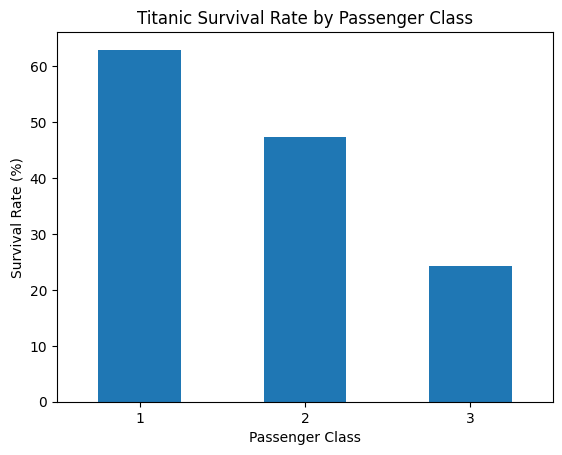

In [ ]:

import matplotlib.pyplot as plt

# Calculate survival rate by passenger class
class_survival = df.groupby("Pclass")["Survived"].mean() * 100

# Create bar chart
class_survival.plot(kind="bar")

plt.title("Titanic Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate (%)")
plt.xticks(rotation=0)
plt.show()


In [ ]:

print("===== TITANIC DATA ANALYSIS SUMMARY =====")

print("\nTotal passengers:", len(df))

print("\nTotal survivors:", df["Survived"].sum())

print("\nOverall survival rate (%):",
      round(df["Survived"].mean() * 100, 2))

print("\nSurvival rate by gender (%):")
print((df.groupby("Sex")["Survived"].mean() * 100).round(2))

print("\nSurvival rate by passenger class (%):")
print((df.groupby("Pclass")["Survived"].mean() * 100).round(2))

print("\nMissing values in Age:", df["Age"].isnull().sum())
print("Missing values in Embarked:", df["Embarked"].isnull().sum())
print("Missing values in Fare:", df["Fare"].isnull().sum())


===== TITANIC DATA ANALYSIS SUMMARY =====

Total passengers: 891

Total survivors: 342

Overall survival rate (%): 38.38

Survival rate by gender (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64

Survival rate by passenger class (%):
Pclass
1    62.96
2    47.28
3    24.24
Name: Survived, dtype: float64

Missing values in Age: 0
Missing values in Embarked: 0
Missing values in Fare: 0
